In [4]:
#1. Import Library
import math
from collections import Counter, defaultdict
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from nltk.util import bigrams, trigrams

pd.set_option("display.max_colwidth", 100)
print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [2]:
#2. Load Dataset
candidate_paths = [
    Path("../dataset/dataset_preprocessed.csv"),
    Path("dataset_preprocessed.csv"),
    Path("../output/dataset_preprocessed.csv"),
    Path("/mnt/data/dataset_preprocessed.csv"),
]

dataset_path = next((p for p in candidate_paths if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "File dataset_preprocessed.csv tidak ditemukan. Letakkan file di folder dataset/output "
        "atau sesuaikan candidate_paths."
    )

df = pd.read_csv(dataset_path)
text_column = "processed_text"
if text_column not in df.columns:
    raise KeyError(f"Kolom {text_column!r} tidak ditemukan. Kolom tersedia: {df.columns.tolist()}")

print("Lokasi dataset:", dataset_path)
print("Ukuran dataset:", df.shape)
print("Jumlah dokumen awal:", len(df))
print("Jumlah nilai kosong pada processed_text:", df[text_column].isna().sum())
display(df[[text_column]].head())

Lokasi dataset: dataset_preprocessed.csv
Ukuran dataset: (220051, 14)
Jumlah dokumen awal: 220051
Jumlah nilai kosong pada processed_text: 10155


,processed_text
0,beliau bilang untung nya m
1,makasih mas
2,gimana untung nya m barang yg jual ajh ga m
3,sticker bilang makasih mas udah m
4,NaN


In [5]:
#3.Membuat Corpus Token
df = df.dropna(subset=[text_column]).copy()
df[text_column] = df[text_column].astype(str).str.strip()
df = df[df[text_column] != ""]

all_text = " ".join(df[text_column])
tokens = all_text.split()
print(f"Jumlah dokumen yang digunakan: {len(df):,}")
print(f"Total token: {len(tokens):,}")
print("Contoh 20 token pertama:", tokens[:20])

Jumlah dokumen yang digunakan: 209,733
Total token: 1,346,751
Contoh 20 token pertama: ['beliau', 'bilang', 'untung', 'nya', 'm', 'makasih', 'mas', 'gimana', 'untung', 'nya', 'm', 'barang', 'yg', 'jual', 'ajh', 'ga', 'm', 'sticker', 'bilang', 'makasih']


In [6]:
#4. Membuat Unigram
unigram = Counter(tokens)
print("20 kata paling sering muncul:")
display(pd.DataFrame(unigram.most_common(20), columns=["Kata", "Frekuensi"]))

20 kata paling sering muncul:


,Kata,Frekuensi
0,yg,29288
1,nya,20581
2,aja,15706
3,ya,13391
4,ga,12296
5,harga,12226
6,gak,11664
7,warung,11463
8,indomaret,9845
9,koperasi,9606


In [7]:
#5. Menghitung Probabilitas Unigram
total_tokens = sum(unigram.values())
unigram_probability = {word: count / total_tokens for word, count in unigram.items()}
top_unigram_prob = sorted(unigram_probability.items(), key=lambda x: x[1], reverse=True)[:10]
print("10 kata dengan probabilitas tertinggi:")
display(pd.DataFrame(top_unigram_prob, columns=["Kata", "Probabilitas"]))
print("Lima contoh probabilitas unigram:")
for word, count in unigram.most_common(5):
    print(f"P({word}) = {count}/{total_tokens} = {unigram_probability[word]:.8f}")

10 kata dengan probabilitas tertinggi:


,Kata,Probabilitas
0,yg,0.021747
1,nya,0.015282
2,aja,0.011662
3,ya,0.009943
4,ga,0.009130
5,harga,0.009078
6,gak,0.008661
7,warung,0.008512
8,indomaret,0.007310
9,koperasi,0.007133


Lima contoh probabilitas unigram:
P(yg) = 29288/1346751 = 0.02174715
P(nya) = 20581/1346751 = 0.01528196
P(aja) = 15706/1346751 = 0.01166214
P(ya) = 13391/1346751 = 0.00994319
P(ga) = 12296/1346751 = 0.00913012


In [8]:
#6. Membuat Bigram
bigram_frequency = Counter(bigrams(tokens))
print("20 bigram paling sering muncul:")
display(pd.DataFrame([(" ".join(k), v) for k, v in bigram_frequency.most_common(20)], columns=["Bigram", "Frekuensi"]))

20 bigram paling sering muncul:


,Bigram,Frekuensi
0,merah putih,5806
1,koperasi merah,2795
2,alfa indo,2610
3,warung madura,2539
4,indomaret alfamart,2293
5,alfamart indomaret,1710
6,indo alfa,1382
7,harga murah,1320
8,lapang kerja,1194
9,koprasi merah,1155


In [9]:
#7. Membuat Trigram
trigram_frequency = Counter(trigrams(tokens))
print("20 trigram paling sering muncul:")
display(pd.DataFrame([(" ".join(k), v) for k, v in trigram_frequency.most_common(20)], columns=["Trigram", "Frekuensi"]))

20 trigram paling sering muncul:


,Trigram,Frekuensi
0,koperasi merah putih,2736
1,koprasi merah putih,1123
2,kopdes merah putih,392
3,buka lapang kerja,301
4,lengkap warung madura,279
5,mending warung madura,257
6,buang buang anggar,234
7,mending beli warung,224
8,beli warung tetangga,214
9,koperasi simpan pinjam,202


In [10]:
#8. Conditional Probability Bigram
def bigram_probability(word1, word2):
    denominator = unigram[word1]
    if denominator == 0:
        return 0.0
    return bigram_frequency[(word1, word2)] / denominator

# Lima kata/kombinasi untuk demonstrasi. Kata diambil dari token yang benar-benar ada di corpus.
contoh_kata = [word for word, _ in unigram.most_common(5)]
rows = []
for word in contoh_kata:
    rows.append({
        "Kata": word,
        "Frekuensi": unigram[word],
        "Probabilitas unigram": unigram_probability[word],
        "Contoh kata berikutnya": max(
            ((w2, c) for (w1, w2), c in bigram_frequency.items() if w1 == word),
            key=lambda x: x[1], default=("(tidak ada)", 0)
        )[0],
    })
display(pd.DataFrame(rows))

# Conditional probability dari 5 bigram paling sering
rows = []
for (w1, w2), count in bigram_frequency.most_common(5):
    rows.append({"Bigram": f"{w1} {w2}", "Count bigram": count, "Count kata pertama": unigram[w1],
                 "P(kata kedua | kata pertama)": bigram_probability(w1, w2)})
display(pd.DataFrame(rows))

,Kata,Frekuensi,Probabilitas unigram,Contoh kata berikutnya
0,yg,29288,0.021747,jual
1,nya,20581,0.015282,aja
2,aja,15706,0.011662,yg
3,ya,13391,0.009943,allah
4,ga,12296,0.009130,sih


,Bigram,Count bigram,Count kata pertama,P(kata kedua | kata pertama)
0,merah putih,5806,6404,0.906621
1,koperasi merah,2795,9606,0.290964
2,alfa indo,2610,8544,0.305478
3,warung madura,2539,11463,0.221495
4,indomaret alfamart,2293,9845,0.232910


In [11]:
#9.  Probabilitas Kalimat
vocab_size = len(unigram)

def smoothed_bigram_probability(word1, word2):
    return (bigram_frequency[(word1, word2)] + 1) / (unigram[word1] + vocab_size)

def sentence_probability(sentence, smoothing=False):
    words = str(sentence).lower().split()
    if len(words) < 2:
        return 1.0 if words else 0.0
    probability = 1.0
    for w1, w2 in bigrams(words):
        p = smoothed_bigram_probability(w1, w2) if smoothing else bigram_probability(w1, w2)
        probability *= p
    return probability

test_sentences = [
    "saya belajar nlp",
    "data teks diproses",
    "model bahasa memprediksi kata",
    "tokenisasi membagi teks",
    "analisis bahasa menggunakan data",
]
rows = []
for sentence in test_sentences:
    rows.append({
        "Kalimat": sentence,
        "Probabilitas tanpa smoothing": sentence_probability(sentence, False),
        "Probabilitas dengan Laplace smoothing": sentence_probability(sentence, True),
    })
display(pd.DataFrame(rows))

,Kalimat,Probabilitas tanpa smoothing,Probabilitas dengan Laplace smoothing
0,saya belajar nlp,0.0,7.157799e-10
1,data teks diproses,0.0,7.122922e-10
2,model bahasa memprediksi kata,0.0,1.893176e-14
3,tokenisasi membagi teks,0.0,7.158374e-10
4,analisis bahasa menggunakan data,0.0,1.912367e-14


In [12]:
#10. Laplace Smoothing
vocab_size = len(unigram)
def smoothed_bigram_probability(word1, word2):
    return (bigram_frequency[(word1, word2)] + 1) / (unigram[word1] + vocab_size)

# Pilih kata umum sebagai konteks dan kata uji yang belum tentu pernah mengikutinya
word1 = unigram.most_common(1)[0][0]
word2 = "contohkata_yang_tidak_ada"
print("Konteks:", word1)
print("Kata berikutnya:", word2)
print("Probabilitas tanpa smoothing:", bigram_probability(word1, word2))
print("Probabilitas dengan Laplace smoothing:", smoothed_bigram_probability(word1, word2))

Konteks: yg
Kata berikutnya: contohkata_yang_tidak_ada
Probabilitas tanpa smoothing: 0.0
Probabilitas dengan Laplace smoothing: 1.500060002400096e-05


In [13]:
#11. Prediksi Kata Berikutnya
def predict_next_word(context_word, top_n=5):
    candidates = []
    for (word1, word2), count in bigram_frequency.items():
        if word1 == context_word:
            candidates.append((word2, smoothed_bigram_probability(word1, word2)))
    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:top_n]

context_words = list(dict.fromkeys(w1 for (w1, w2), count in bigram_frequency.most_common(1000)))[:5]
for context in context_words:
    print(f"\nPrediksi setelah kata '{context}':")
    predictions = predict_next_word(context, top_n=5)
    if predictions:
        for word, prob in predictions:
            print(f"  {word:<25} {prob:.8f}")
    else:
        print("  Tidak ada kandidat bigram untuk konteks ini.")


Prediksi setelah kata 'merah':
  putih                     0.13264048
  biru                      0.00201005
  si                        0.00068524
  hitam                     0.00066240
  kuning                    0.00038831

Prediksi setelah kata 'koperasi':
  merah                     0.05951215
  desa                      0.01651696
  simpan                    0.00464007
  yg                        0.00436337
  nya                       0.00351198

Prediksi setelah kata 'alfa':
  indo                      0.05685976
  indomaret                 0.02051394
  indomart                  0.01284843
  mart                      0.00760017
  aja                       0.00331010

Prediksi setelah kata 'warung':
  madura                    0.05200762
  tetangga                  0.01668748
  warung                    0.01148672
  yg                        0.00548742
  kelontong                 0.00513934

Prediksi setelah kata 'indomaret':
  alfamart                  0.04858008
  alfa        

In [14]:
#12. Menghitung Perplexity
def sentence_perplexity(sentence):
    words = str(sentence).lower().split()
    if not words:
        return float("inf")
    if len(words) < 2:
        return 1.0
    log_probability = sum(math.log(smoothed_bigram_probability(w1, w2)) for w1, w2 in bigrams(words))
    return math.exp(-log_probability / (len(words) - 1))

print("Perplexity untuk setiap kalimat uji:")
for sentence in test_sentences:
    print(f"{sentence} -> perplexity = {sentence_perplexity(sentence):.6f}")

Perplexity untuk setiap kalimat uji:
saya belajar nlp -> perplexity = 37377.499970
data teks diproses -> perplexity = 37468.896661
model bahasa memprediksi kata -> perplexity = 37520.590255
tokenisasi membagi teks -> perplexity = 37376.000000
analisis bahasa menggunakan data -> perplexity = 37394.662332


In [15]:
#13. Perbandingan Unigram, Bigram, dan Trigram
print(f"Jumlah dokumen             : {len(df):,}")
print(f"Jumlah token               : {len(tokens):,}")
print(f"Ukuran vocabulary          : {len(unigram):,}")
print(f"Jumlah unigram unik        : {len(unigram):,}")
print(f"Jumlah bigram unik         : {len(bigram_frequency):,}")
print(f"Jumlah trigram unik        : {len(trigram_frequency):,}")
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan bigram teoritis: {max_bigram:,}")
print(f"Kemungkinan trigram teoritis: {max_trigram:,}")
print(f"Coverage bigram teoritis   : {len(bigram_frequency) / max_bigram * 100:.6f}%")

Jumlah dokumen             : 209,733
Jumlah token               : 1,346,751
Ukuran vocabulary          : 37,376
Jumlah unigram unik        : 37,376
Jumlah bigram unik         : 409,830
Jumlah trigram unik        : 718,650
Kemungkinan bigram teoritis: 1,396,965,376
Kemungkinan trigram teoritis: 52,212,977,893,376
Coverage bigram teoritis   : 0.029337%


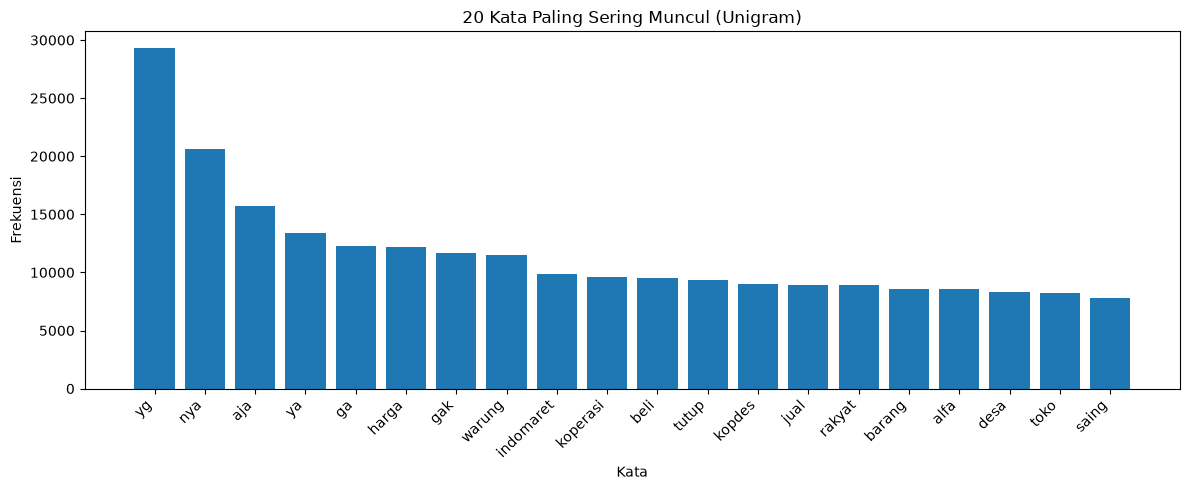

In [16]:
#14.  Visualisasi
top_words = unigram.most_common(20)
words_list = [item[0] for item in top_words]
counts_list = [item[1] for item in top_words]

plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()

In [17]:
#E. Analisis dan Perbandingan
import pandas as pd

# Perbandingan jumlah N-Gram
hasil_perbandingan = pd.DataFrame({
    "Model": ["Unigram", "Bigram", "Trigram"],
    "Jumlah N-Gram Unik": [
        len(unigram),
        len(bigram_frequency),
        len(trigram_frequency)
    ],
    "Panjang Konteks": [
        "1 kata",
        "2 kata",
        "3 kata"
    ],
    "Kelebihan": [
        "Sederhana dan mudah dihitung",
        "Menangkap hubungan dua kata",
        "Menangkap hubungan tiga kata"
    ],
    "Kekurangan": [
        "Tidak menangkap hubungan antarkata",
        "Konteks masih terbatas",
        "Lebih rentan terhadap sparsity"
    ]
})

display(hasil_perbandingan)

# Menampilkan kata, pasangan kata, dan tiga kata yang paling sering muncul
print("\n20 UNIGRAM PALING SERING MUNCUL")
display(pd.DataFrame(
    unigram.most_common(20),
    columns=["Kata", "Frekuensi"]
))

print("\n20 BIGRAM PALING SERING MUNCUL")
display(pd.DataFrame(
    bigram_frequency.most_common(20),
    columns=["Pasangan Kata", "Frekuensi"]
))

print("\n20 TRIGRAM PALING SERING MUNCUL")
display(pd.DataFrame(
    trigram_frequency.most_common(20),
    columns=["Tiga Kata", "Frekuensi"]
))

# Analisis jumlah kombinasi dan sparsity
vocab_size = len(unigram)
max_bigram = vocab_size ** 2
max_trigram = vocab_size ** 3

print("\nANALISIS UKURAN MODEL")
print(f"Jumlah token              : {len(tokens):,}")
print(f"Ukuran vocabulary         : {vocab_size:,}")
print(f"Jumlah unigram unik       : {len(unigram):,}")
print(f"Jumlah bigram unik        : {len(bigram_frequency):,}")
print(f"Jumlah trigram unik       : {len(trigram_frequency):,}")
print(f"Bigram coverage teoritis  : {len(bigram_frequency) / max_bigram * 100:.6f}%")
print(f"Trigram coverage teoritis : {len(trigram_frequency) / max_trigram * 100:.10f}%")

,Model,Jumlah N-Gram Unik,Panjang Konteks,Kelebihan,Kekurangan
0,Unigram,37376,1 kata,Sederhana dan mudah dihitung,Tidak menangkap hubungan antarkata
1,Bigram,409830,2 kata,Menangkap hubungan dua kata,Konteks masih terbatas
2,Trigram,718650,3 kata,Menangkap hubungan tiga kata,Lebih rentan terhadap sparsity



20 UNIGRAM PALING SERING MUNCUL


,Kata,Frekuensi
0,yg,29288
1,nya,20581
2,aja,15706
3,ya,13391
4,ga,12296
5,harga,12226
6,gak,11664
7,warung,11463
8,indomaret,9845
9,koperasi,9606



20 BIGRAM PALING SERING MUNCUL


,Pasangan Kata,Frekuensi
0,"(merah, putih)",5806
1,"(koperasi, merah)",2795
2,"(alfa, indo)",2610
3,"(warung, madura)",2539
4,"(indomaret, alfamart)",2293
5,"(alfamart, indomaret)",1710
6,"(indo, alfa)",1382
7,"(harga, murah)",1320
8,"(lapang, kerja)",1194
9,"(koprasi, merah)",1155



20 TRIGRAM PALING SERING MUNCUL


,Tiga Kata,Frekuensi
0,"(koperasi, merah, putih)",2736
1,"(koprasi, merah, putih)",1123
2,"(kopdes, merah, putih)",392
3,"(buka, lapang, kerja)",301
4,"(lengkap, warung, madura)",279
5,"(mending, warung, madura)",257
6,"(buang, buang, anggar)",234
7,"(mending, beli, warung)",224
8,"(beli, warung, tetangga)",214
9,"(koperasi, simpan, pinjam)",202



ANALISIS UKURAN MODEL
Jumlah token              : 1,346,751
Ukuran vocabulary         : 37,376
Jumlah unigram unik       : 37,376
Jumlah bigram unik        : 409,830
Jumlah trigram unik       : 718,650
Bigram coverage teoritis  : 0.029337%
Trigram coverage teoritis : 0.0000013764%


### a. Analisis Unigram

Unigram digunakan untuk menghitung frekuensi kemunculan setiap kata dalam kolom `processed_text`. Melalui hasil 20 kata teratas, dapat diketahui kata-kata yang paling sering digunakan dalam dataset komentar. Frekuensi tersebut memberikan gambaran mengenai kosakata yang dominan. Namun, unigram belum dapat menjelaskan hubungan suatu kata dengan kata sebelum atau sesudahnya.

### b. Analisis Bigram

Bigram menghitung kemunculan pasangan dua kata yang berurutan. Dibandingkan unigram, bigram memberikan informasi konteks yang lebih baik karena dapat menunjukkan pasangan kata yang sering digunakan bersama dalam komentar. Akan tetapi, bigram hanya mempertimbangkan hubungan antara dua kata sehingga konteks yang dipahami model masih terbatas.

### c. Analisis Trigram

Trigram menghitung urutan tiga kata yang berdekatan. Model ini dapat menangkap konteks yang lebih panjang daripada unigram dan bigram. Hasil trigram dapat digunakan untuk melihat rangkaian kata yang sering muncul bersama. Meskipun demikian, jumlah kombinasi yang mungkin terbentuk semakin besar sehingga banyak rangkaian kata memiliki frekuensi rendah atau tidak ditemukan dalam dataset.

### d. Perbandingan Ketiga Model

| Aspek | Unigram | Bigram | Trigram |
|---|---|---|---|
| Konteks | Satu kata | Dua kata berurutan | Tiga kata berurutan |
| Informasi | Frekuensi kata | Hubungan pasangan kata | Hubungan rangkaian tiga kata |
| Kompleksitas | Rendah | Sedang | Lebih tinggi |
| Sparsity | Relatif lebih rendah | Lebih tinggi | Cenderung paling tinggi |
| Penggunaan | Mengetahui kata dominan | Prediksi berdasarkan satu kata sebelumnya | Prediksi berdasarkan dua kata sebelumnya |

### e. Analisis Sparsity

Sparsity merupakan kondisi ketika banyak kemungkinan kombinasi kata tidak muncul dalam korpus. Pada dataset komentar yang memiliki kosakata beragam, kondisi ini perlu diperhatikan. Ketika panjang N-Gram meningkat, kombinasi kata yang mungkin terbentuk juga bertambah. Akibatnya, model trigram cenderung memiliki lebih banyak kombinasi dengan frekuensi rendah dibandingkan model bigram.

Nilai *coverage* yang dihitung oleh kode menunjukkan persentase kombinasi yang teramati dibandingkan dengan jumlah kombinasi teoritis. Nilai ini merupakan gambaran sederhana tentang kelangkaan kombinasi, bukan ukuran lengkap kualitas model bahasa.

### f. Keterbatasan N-Gram

Berdasarkan karakteristik ketiga model, terdapat beberapa keterbatasan yang perlu diperhatikan:

1. **Sparsity:** Banyak kombinasi kata tidak ditemukan dalam korpus sehingga dapat menghasilkan probabilitas nol.
2. **Konteks terbatas:** Bigram hanya melihat satu kata sebelumnya, sedangkan trigram melihat dua kata sebelumnya.
3. **Tidak memahami makna:** Model menghitung pola berdasarkan token dan frekuensi, bukan memahami makna kata secara langsung.
4. **Ketergantungan pada dataset:** Kata atau pola yang jarang muncul sulit diprediksi secara akurat.
5. **Kebutuhan smoothing:** *Laplace smoothing* dapat membantu menghindari probabilitas nol pada bigram yang tidak ditemukan.

## 3. Kesimpulan Analisis

Berdasarkan perbandingan unigram, bigram, dan trigram, setiap model memiliki fungsi yang berbeda dalam menganalisis teks pada dataset `processed_text`. Unigram cocok untuk melihat frekuensi kata, bigram memberikan informasi tentang hubungan dua kata, sedangkan trigram menangkap konteks tiga kata yang lebih panjang.

Trigram memiliki potensi memberikan konteks yang lebih spesifik, tetapi juga lebih rentan terhadap sparsity. Oleh karena itu, pemilihan model perlu disesuaikan dengan tujuan analisis dan karakteristik dataset. Penggunaan *Laplace smoothing* dapat membantu mengatasi probabilitas nol, tetapi tidak menghilangkan seluruh keterbatasan model N-Gram.